## CartWise AI: Exploratory Data Analysis

### load, cleaning report, missing values, ratings

In [8]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROC = ROOT / 'data' / 'processed'
inter = pd.read_parquet(PROC / 'interactions.parquet')
products = pd.read_parquet(PROC / 'products.parquet')
print('interactions:', inter.shape, '| products:', products.shape)
inter.head()

interactions: (136688, 4) | products: (19277, 10)


,item_id,user_id,rating,timestamp
0,B0002X9A5G,A2X2UXJ61WYG6Q,5.0,1147910400
1,B0006SUTQ6,A2X2UXJ61WYG6Q,3.0,1147910400
2,B0006SUTRK,A2X2UXJ61WYG6Q,4.0,1147910400
3,B0009NDUPA,A3GMV6W1LOL1UK,5.0,1163116800
4,B0009NDUPK,A3GMV6W1LOL1UK,5.0,1163116800


In [9]:
report_path = PROC / 'cleaning_report.json'
if report_path.exists():
    report = json.loads(report_path.read_text())
    for part, values in report.items():
        print(part)
        for k, v in values.items():
            print('   ', k, ':', v)
else:
    print('cleaning_report.json not found. Copy it from Google Drive together with the parquet files.')
    

ratings
    rows_in : 883636
    dropped_missing_values : 0
    dropped_empty_ids : 0
    dropped_invalid_rating : 0
    dropped_duplicate_user_item : 8515
    rows_out : 875121
metadata
    rows_in : 186637
    dropped_missing_asin : 0
    titles_with_scraped_code : 433
    dropped_duplicate_asin : 443
    dropped_no_title : 33
    rows_out : 186161
    pct_with_price : 9.55
    pct_with_image : 70.8
    pct_with_brand : 75.02
    pct_rich_text : 10.26
join_and_filter
    interactions_in : 875121
    dropped_no_metadata : 134
    after_activity_filter : 136688
    final_interactions : 136688
    final_users : 58417
    final_products : 19277
    u_min : 2
    i_min : 2
    max_users : None
    seed : 42


In [10]:
print(inter.dtypes, '\n')
print(products.dtypes, '\n')

def filled_pct(s):
    ok = s.map(lambda v: not (v is None or (isinstance(v, float) and np.isnan(v)) or (isinstance(v, str) and v == '')))
    return round(float(ok.mean() * 100), 2)

print('Share of products with each field filled (%)')
print(products.drop(columns=['text', 'rich_text']).apply(filled_pct).sort_values(), '\n')
print('duplicate (user, item) rows:', int(inter.duplicated(['user_id', 'item_id']).sum()))
print('duplicate product ids     :', int(products['item_id'].duplicated().sum()))
print('ratings outside 1-5       :', int((~inter['rating'].between(1, 5)).sum()))
print('missing values in interactions:'); print(inter.isna().sum())

item_id          str
user_id          str
rating       float64
timestamp      int64
dtype: object 

item_id            str
title              str
brand              str
features           str
description        str
category           str
price          float64
image_url          str
text               str
rich_text         bool
dtype: object 

Share of products with each field filled (%)
category         0.00
description     11.97
features        14.10
price           18.14
brand           76.89
image_url       81.38
item_id        100.00
title          100.00
dtype: float64 

duplicate (user, item) rows: 0
duplicate product ids     : 0
ratings outside 1-5       : 0
missing values in interactions:
item_id      0
user_id      0
rating       0
timestamp    0
dtype: int64


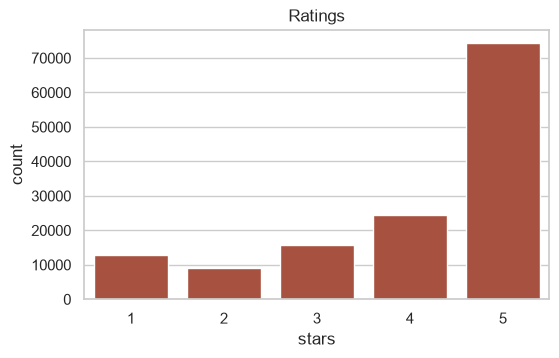

rating
1.0     9.3
2.0     6.7
3.0    11.5
4.0    17.9
5.0    54.5
Name: proportion, dtype: float64


In [11]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.countplot(x=inter['rating'].astype(int), ax=ax, color='#b8452f')
ax.set_title('Ratings'); ax.set_xlabel('stars'); plt.show()
print((inter['rating'].value_counts(normalize=True).sort_index() * 100).round(1))

## Cells 5 to 8: users, products, brands, time

count    58417.00
mean         2.34
std          0.99
min          2.00
25%          2.00
50%          2.00
75%          2.00
max         31.00
dtype: float64


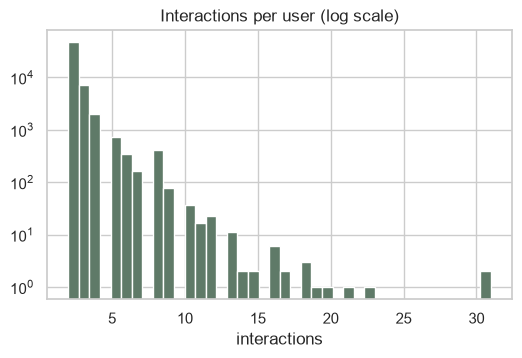

users with exactly 2 interactions: 81.0 %
users with 5+ interactions       : 3.1 %


In [12]:
per_user = inter.groupby('user_id').size()
print(per_user.describe().round(2))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(per_user, bins=40, color='#5f7a68'); ax.set_yscale('log')
ax.set_title('Interactions per user (log scale)'); ax.set_xlabel('interactions'); plt.show()
print('users with exactly 2 interactions:', round(float((per_user == 2).mean() * 100), 1), '%')
print('users with 5+ interactions       :', round(float((per_user >= 5).mean() * 100), 1), '%')

count    19277.00
mean         7.09
std         55.71
min          2.00
25%          2.00
50%          3.00
75%          5.00
max       4332.00
dtype: float64


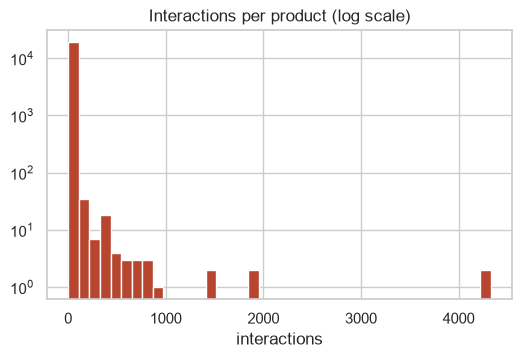

,item_id,interactions,title,brand
0,B000KPIHQ4,4332,Powerstep Pinnacle Orthotic Shoe Insoles,
1,B000V0IBDM,4332,Powerstep Pinnacle Orthotic Shoe Insoles,
2,B00201ER88,1949,"i play. Baby Solid Brim Sun Protection Hat, Aq...",i play.
3,B000P0X15G,1922,"i play. Girls' Baby Brim Sun Protection Hat, A...",i play.
4,B000GHRZN2,1418,Carhartt Men's Loose Fit Five Pocket Canvas Ca...,
5,B000GHMRLW,1418,Carhartt Men's Loose Fit Five Pocket Canvas Ca...,
6,B000YFSR5G,881,Hanes Mens EcoSmart Fleece Sweatpant,
7,B000YFSR4W,825,Hanes Mens EcoSmart Fleece Sweatpant,
8,B009PMILQE,795,Allegra K Women Boat Neck Batwing Sleeves Pull...,Allegra K
9,B00RLSCLJM,794,MJ Metals Jewelry 2mm to 10mm White Tungsten C...,MJ Metals Jewelry


In [13]:
per_item = inter.groupby('item_id').size()
print(per_item.describe().round(2))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(per_item, bins=40, color='#b8452f'); ax.set_yscale('log')
ax.set_title('Interactions per product (log scale)'); ax.set_xlabel('interactions'); plt.show()

top = per_item.sort_values(ascending=False).head(10).rename('interactions').reset_index()
top = top.merge(products[['item_id', 'title', 'brand']], on='item_id', how='left')
top

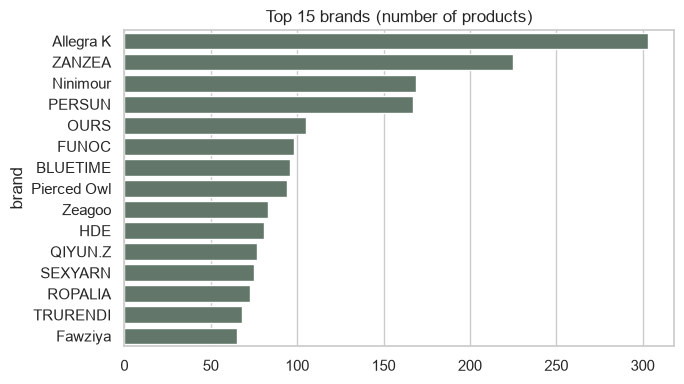

products with a brand   : 14823 of 19277
products with a category: 0 (this dataset has no category field)


In [14]:
brands = products.loc[products['brand'] != '', 'brand'].value_counts().head(15)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=brands.values, y=brands.index, ax=ax, color='#5f7a68')
ax.set_title('Top 15 brands (number of products)')
plt.tight_layout(); plt.show()
print('products with a brand   :', int((products['brand'] != '').sum()), 'of', len(products))
print('products with a category:', int((products['category'] != '').sum()), '(this dataset has no category field)')

date range: 2006-05-18 00:00:00 to 2018-09-29 00:00:00


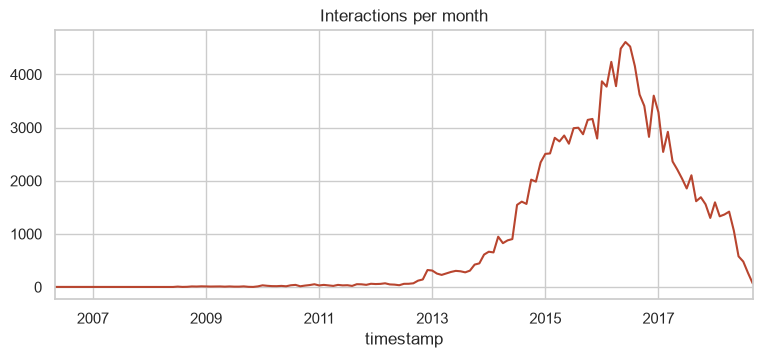

In [15]:
dates = pd.to_datetime(inter['timestamp'], unit='s')
print('date range:', dates.min(), 'to', dates.max())
monthly = dates.dt.to_period('M').value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.5))
monthly.plot(ax=ax, color='#b8452f'); ax.set_title('Interactions per month'); plt.show()

## Cells 9 to 11: availability, text length, variants

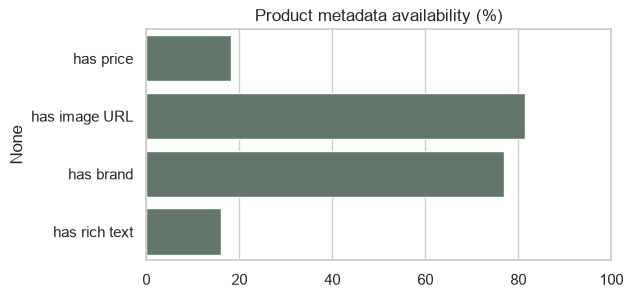

has price        18.1
has image URL    81.4
has brand        76.9
has rich text    16.1
dtype: float64

price summary
count    3497.00
mean       19.74
std        31.15
min         0.13
25%         8.17
50%        12.00
75%        19.99
max       999.99
Name: price, dtype: float64


In [16]:
avail = pd.Series({
    'has price': products['price'].notna().mean() * 100,
    'has image URL': products['image_url'].notna().mean() * 100,
    'has brand': (products['brand'] != '').mean() * 100,
    'has rich text': products['rich_text'].mean() * 100,
})
fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(x=avail.values, y=avail.index, ax=ax, color='#5f7a68'); ax.set_xlim(0, 100)
ax.set_title('Product metadata availability (%)'); plt.show()
print(avail.round(1))
print('\nprice summary'); print(products['price'].describe().round(2))

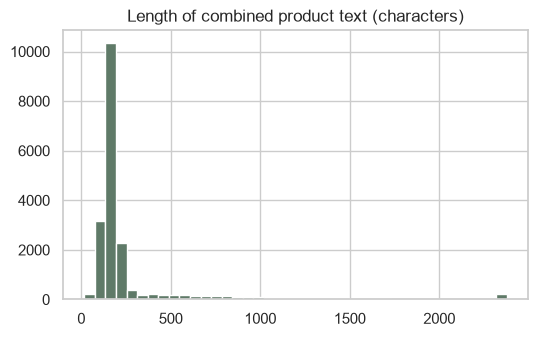

count    19277.0
mean       293.7
std        439.2
min         17.0
25%        146.0
50%        168.0
75%        202.0
max       4750.0
Name: text, dtype: float64
share with rich text (description or features): 16.1 %


In [17]:
lengths = products['text'].str.len()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(lengths.clip(upper=lengths.quantile(0.99)), bins=40, color='#5f7a68')
ax.set_title('Length of combined product text (characters)'); plt.show()
print(lengths.describe().round(1))
print('share with rich text (description or features):', round(float(products['rich_text'].mean() * 100), 1), '%')

In [18]:
norm = products['title'].str.lower().str.replace(r'[^a-z0-9]+', ' ', regex=True).str.strip()
print('products whose title is shared with another product:', round(float(norm.duplicated(keep=False).mean() * 100), 1), '%')
print('distinct titles:', int(norm.nunique()), 'of', len(products), 'products')
norm.value_counts().head(5)

products whose title is shared with another product: 8.8 %
distinct titles: 18195 of 19277 products


title
sperry top sider men s halyard 2 eye boat shoes                                   18
sunnow womens long sleeve v neck zipper sexy chiffon pullover t shirt blouse      16
urparcel mens briefs mesh hole thongs shorts low rise g string underwear s m l    15
women s batwing dolman sleeve chiffon bohemian oversized blouse                   12
caribbean joe three quarter sleeve ruched adjustable top                          11
Name: count, dtype: int64